# **APS 2 — Inteligência Artificial Aplicada: Canteiro de Obras Inteligente "Torre Europarque"**
### *Sistemas Inteligentes de Otimização, Conhecimento, Redes Neurais e Lógica Fuzzy na Construção Civil*

* **Instituição:** Centro Universitário UniSENAI PR — Campus Londrina
* **Curso:** Engenharia de Software | 6º Período (2026/2)
* **Disciplina:** Inteligência Artificial Aplicada
* **Docente:** Prof. Paulo Cesar Dias Lima

**Integrantes do Grupo:**

* Felipy Yuske Ogido — RA: `[inserir RA]`
* Fernando Junior Vaciski de Camargo — RA: `[inserir RA]`
* Giovana Nunes Constancio Donato — RA: `01033251`
* Graciele Miki Sazaka — RA: `[inserir RA]`
* João Paulo Simplicio — RA: `[inserir RA]`

*(Representante do Grupo: `A DEFINIR`)*


In [1]:
# ==============================================================================
# CONFIGURAÇÃO DO AMBIENTE E IMPORTS GLOBAIS (TODAS AS ETAPAS)
# ==============================================================================

# Instalação das bibliotecas necessárias no Google Colab
# (PuLP fixado na série 2.x: a versão 4.x mudou a API e quebra pulp.LpVariable(lowBound=...))
!pip install -q "pulp<3" deap simpy rdflib scikit-fuzzy tabulate

# Base, manipulação de dados e visualização
import os
import random
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Etapa 1 — Busca Heurística (A*) e Programação Linear
import networkx as nx
import pulp

# Etapa 2 — Algoritmo Genético (VRP) e Simulação Discreta
from deap import base, creator, tools, algorithms
import simpy

# Etapa 3 — Ontologia RDF/OWL e SPARQL
from rdflib import Graph, Namespace, Literal, URIRef
from rdflib.namespace import RDF, RDFS, OWL, XSD

# Etapa 5 — Lógica Fuzzy
import skfuzzy as fuzz
from skfuzzy import control as ctrl

# Configurações globais de gráficos e pastas de saída
os.makedirs("outputs/graficos", exist_ok=True)
os.makedirs("outputs/tabelas", exist_ok=True)
plt.rcParams["figure.dpi"] = 120

# Semente global para reprodutibilidade (GA, SimPy, MLP)
SEED = 42
random.seed(SEED)
np.random.seed(SEED)

print("Ambiente configurado com sucesso!")

Ambiente configurado com sucesso!


## Etapa 1 — Roteirização (A* em NetworkX) e Alocação de Recursos (PuLP)

### 1a — Busca Heurística A* (Malha 8x8)
O canteiro é modelado como uma malha ortogonal 8x8 (`nx.grid_2d_graph`), com movimentos em 4 direções e custo unitário por passo. Os obstáculos rígidos (andaimes e escavação) em **(3,3)** e **(3,4)** são removidos do grafo. O AGV parte do **Almoxarifado Central (0,0)** até a **Torre de Elevação (7,7)**, e o A* usa a **distância de Manhattan** como heurística h(n), que é admissível nesse tipo de malha (nunca superestima o custo real).

Origem (Almoxarifado Central): (0, 0)
Destino (Torre de Elevação):   (7, 7)
Obstáculos removidos:          [(3, 3), (3, 4)]
Custo total (passos):          14
Caminho ótimo encontrado:
[(0, 0), (1, 0), (2, 0), (3, 0), (4, 0), (5, 0), (6, 0), (7, 0), (7, 1), (7, 2), (7, 3), (7, 4), (7, 5), (7, 6), (7, 7)]

h(início) = 14 passos (limite inferior da heurística)
Caminhos ótimos empatados — sem obstáculos: 3432 | com obstáculos: 1507


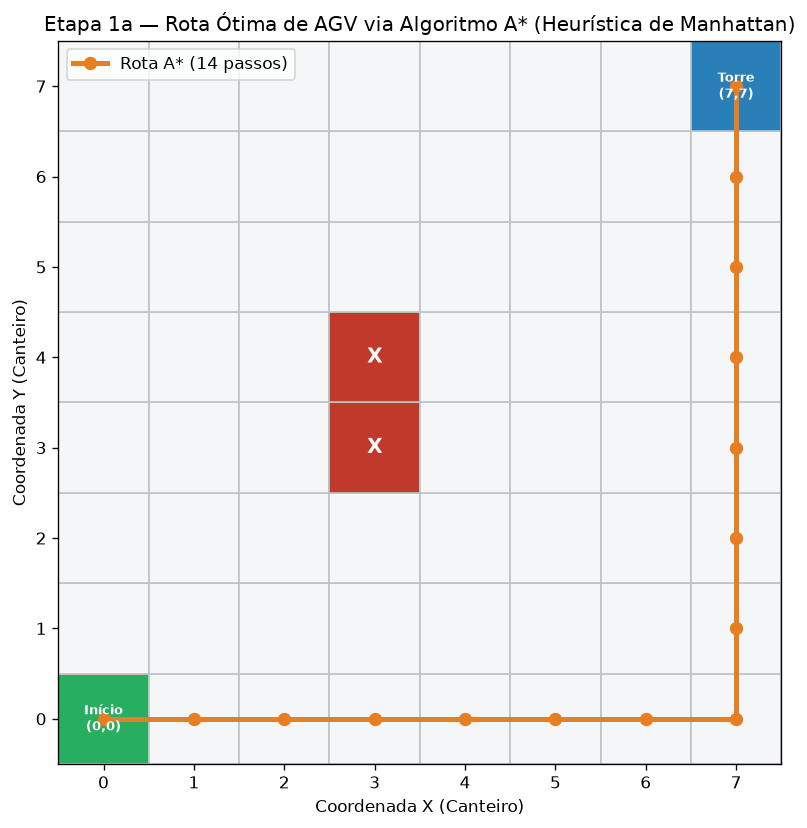

In [2]:
# ==============================================================================
# ETAPA 1a: ROTEAMENTO AUTÔNOMO DE AGVs COM ALGORITMO A* (NETWORKX)
# ==============================================================================

# 1. Criação da malha ortogonal 2D (8x8) representando o canteiro Torre Europarque
G = nx.grid_2d_graph(8, 8)

# 2. Definição dos pontos-chave e obstáculos rígidos (andaimes e escavações)
inicio = (0, 0)       # Almoxarifado Central
destino = (7, 7)      # Torre de Elevação
obstaculos = [(3, 3), (3, 4)]

# Remove os nós bloqueados do grafo
G.remove_nodes_from(obstaculos)

# 3. Definição da heurística admissível: Distância de Manhattan h(n)
def heuristica_manhattan(u, v):
    return abs(u[0] - v[0]) + abs(u[1] - v[1])

# 4. Execução do algoritmo A*
caminho_otimo = nx.astar_path(G, inicio, destino, heuristic=heuristica_manhattan)
custo_total = nx.astar_path_length(G, inicio, destino, heuristic=heuristica_manhattan)

print(f"Origem (Almoxarifado Central): {inicio}")
print(f"Destino (Torre de Elevação):   {destino}")
print(f"Obstáculos removidos:          {obstaculos}")
print(f"Custo total (passos):          {custo_total}")
print(f"Caminho ótimo encontrado:\n{caminho_otimo}")

# Quantos caminhos distintos têm o mesmo custo mínimo? (com e sem obstáculos)
G_livre = nx.grid_2d_graph(8, 8)
n_otimos_livre = len(list(nx.all_shortest_paths(G_livre, inicio, destino)))
n_otimos_obst = len(list(nx.all_shortest_paths(G, inicio, destino)))
print(f"\nh(início) = {heuristica_manhattan(inicio, destino)} passos (limite inferior da heurística)")
print(f"Caminhos ótimos empatados — sem obstáculos: {n_otimos_livre} | com obstáculos: {n_otimos_obst}")

# 5. Visualização gráfica da malha e da rota
fig, ax = plt.subplots(figsize=(7, 7))

# Desenha a grade 8x8
for x in range(8):
    for y in range(8):
        cor = "#F4F6F7"
        if (x, y) in obstaculos:
            cor = "#C0392B"  # Vermelho para obstáculos
        elif (x, y) == inicio:
            cor = "#27AE60"  # Verde para origem
        elif (x, y) == destino:
            cor = "#2980B9"  # Azul para destino
        rect = plt.Rectangle((x - 0.5, y - 0.5), 1, 1, facecolor=cor, edgecolor="#BDC3C7", lw=1)
        ax.add_patch(rect)

# Plota o caminho ótimo
xs = [p[0] for p in caminho_otimo]
ys = [p[1] for p in caminho_otimo]
ax.plot(xs, ys, color="#E67E22", linewidth=3, marker="o", markersize=7, label=f"Rota A* ({custo_total} passos)")

# Anotações de texto nos pontos principais
ax.text(inicio[0], inicio[1], "Início\n(0,0)", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
ax.text(destino[0], destino[1], "Torre\n(7,7)", ha="center", va="center", color="white", fontweight="bold", fontsize=8)
for ox, oy in obstaculos:
    ax.text(ox, oy, "X", ha="center", va="center", color="white", fontweight="bold", fontsize=12)

ax.set_xlim(-0.5, 7.5)
ax.set_ylim(-0.5, 7.5)
ax.set_xticks(range(8))
ax.set_yticks(range(8))
ax.set_xlabel("Coordenada X (Canteiro)")
ax.set_ylabel("Coordenada Y (Canteiro)")
ax.set_title("Etapa 1a — Rota Ótima de AGV via Algoritmo A* (Heurística de Manhattan)")
ax.legend(loc="upper left")
ax.set_aspect("equal")

plt.tight_layout()
plt.savefig("outputs/graficos/etapa1a_astar_rota.png", dpi=300)
plt.show()

**Análise dos resultados (1a)**
- O A* encontrou uma rota de **14 passos**, exatamente o valor da heurística no ponto de partida, h(0,0) = |7−0| + |7−0| = 14. Ou seja, a heurística de Manhattan é **exata** nessa malha (não superestima nem subestima), e o A* expande praticamente só os nós que estão no caminho ótimo.
- Os obstáculos em (3,3) e (3,4) **não aumentam o custo**: eles reduzem de **3.432 para 1.507** o número de caminhos ótimos empatados, mas ainda sobram rotas monotônicas (só para direita e para cima) que os contornam.
- Entre os caminhos empatados, o NetworkX devolveu o que segue pela borda do canteiro. Em uma operação real, esse desempate poderia considerar critérios extras, como manter distância de andaimes e escavações ou evitar áreas de circulação de pessoas.

### 1b — Programação Linear com PuLP (Mini-carregadeiras A, B e C)
O enunciado define apenas a demanda mínima de 450 t/dia. Capacidades, custos, disponibilidade e o limite de 10 equipamentos no pátio são **premissas adotadas pelo grupo** (valores ilustrativos), listadas no início da célula. As variáveis são **inteiras**, já que não é possível alocar fração de equipamento.

Status da Solução: Optimal


,Tipo,Alocadas,Capacidade (t),Custo (R$)
0,Mini-carregadeira A,0,0,0
1,Mini-carregadeira B,4,260,2720
2,Mini-carregadeira C,2,190,1840



Total Transportado: 450 t/dia (Meta: >= 450 t/dia)
Custo Operacional Ótimo: R$ 4.560,00/dia
Custo por tonelada: R$ 10,13/t


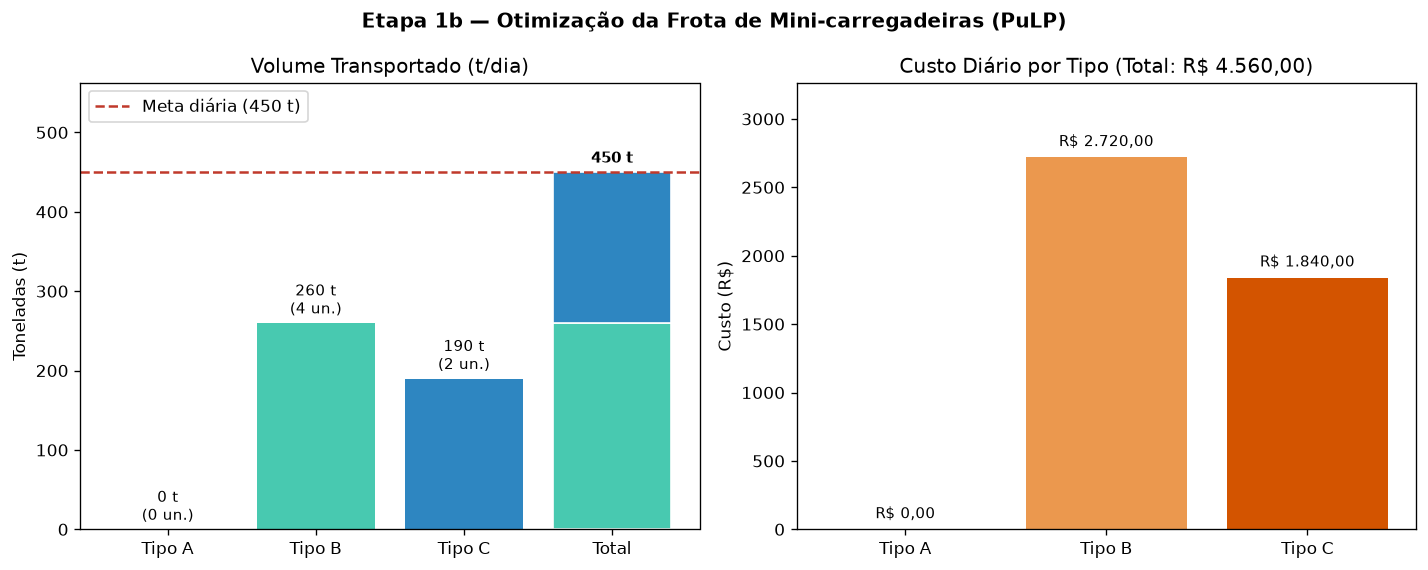

In [3]:
# ==============================================================================
# ETAPA 1b: ALOCAÇÃO ÓTIMA DE MINI-CARREGADEIRAS COM PULP (PL INTEIRA)
# ==============================================================================

# Premissas operacionais adotadas para o canteiro Torre Europarque:
# - Tipo A (Compacta):        40 t/dia | R$ 450,00/dia | Disponibilidade: 6 unid.
# - Tipo B (Média):           65 t/dia | R$ 680,00/dia | Disponibilidade: 6 unid.
# - Tipo C (Alta Capacidade): 95 t/dia | R$ 920,00/dia | Disponibilidade: 4 unid.
# - Demanda mínima diária:    450 toneladas de argamassa
# - Limite de tráfego no pátio: máximo de 10 equipamentos operando simultaneamente

dados_frota = {
    "A": {"capacidade": 40, "custo": 450, "max_disp": 6},
    "B": {"capacidade": 65, "custo": 680, "max_disp": 6},
    "C": {"capacidade": 95, "custo": 920, "max_disp": 4},
}
demanda_minima = 450

def brl(valor):
    """Formata valores no padrão monetário brasileiro (R$ 1.234,56)."""
    return f"R$ {valor:,.2f}".replace(",", "X").replace(".", ",").replace("X", ".")
limite_patio = 10

# 1. Criação do modelo de minimização
modelo = pulp.LpProblem("Alocacao_MiniCarregadeiras_Europarque", pulp.LpMinimize)

# 2. Variáveis de decisão (quantidade inteira de equipamentos alocados)
x = {
    tipo: pulp.LpVariable(f"Qtd_Tipo_{tipo}", lowBound=0, upBound=info["max_disp"], cat="Integer")
    for tipo, info in dados_frota.items()
}

# 3. Função Objetivo: Minimizar o custo operacional diário (R$)
modelo += pulp.lpSum(dados_frota[t]["custo"] * x[t] for t in dados_frota), "Custo_Total_Diario"

# 4. Restrições
# 4.1 Atender no mínimo 450 toneladas/dia
modelo += (
    pulp.lpSum(dados_frota[t]["capacidade"] * x[t] for t in dados_frota) >= demanda_minima,
    "Demanda_Minima_Argamassa"
)
# 4.2 Limite físico de circulação simultânea no canteiro
modelo += (
    pulp.lpSum(x[t] for t in dados_frota) <= limite_patio,
    "Limite_Maximo_Equipamentos"
)

# 5. Resolução
status = modelo.solve(pulp.PULP_CBC_CMD(msg=False))

print(f"Status da Solução: {pulp.LpStatus[status]}")
assert pulp.LpStatus[status] == "Optimal", "O modelo não encontrou solução ótima — revise as premissas."
resumo_pl = []
for t in dados_frota:
    qtd = int(round(x[t].varValue))  # round evita truncar 3.9999 para 3
    ton = qtd * dados_frota[t]["capacidade"]
    custo = qtd * dados_frota[t]["custo"]
    resumo_pl.append({"Tipo": f"Mini-carregadeira {t}", "Alocadas": qtd, "Capacidade (t)": ton, "Custo (R$)": custo})

df_pl = pd.DataFrame(resumo_pl)
display(df_pl)

ton_total = df_pl["Capacidade (t)"].sum()
custo_total_pl = pulp.value(modelo.objective)
print(f"\nTotal Transportado: {ton_total} t/dia (Meta: >= {demanda_minima} t/dia)")
print(f"Custo Operacional Ótimo: {brl(custo_total_pl)}/dia")
print(f"Custo por tonelada: {brl(custo_total_pl / ton_total)}/t")

# 6. Gráfico de alocação e custo
fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))

# Gráfico 1: volume por tipo + total empilhado comparado à meta
cores_tipo = ["#5DADE2", "#48C9B0", "#2E86C1"]
rotulos = [f"Tipo {t}" for t in dados_frota]
axes[0].bar(rotulos, df_pl["Capacidade (t)"], color=cores_tipo)
base = 0
for cor, v in zip(cores_tipo, df_pl["Capacidade (t)"]):
    axes[0].bar("Total", v, bottom=base, color=cor, edgecolor="white")
    base += v
axes[0].axhline(demanda_minima, color="#C0392B", linestyle="--", label=f"Meta diária ({demanda_minima} t)")
for i, (v, q) in enumerate(zip(df_pl["Capacidade (t)"], df_pl["Alocadas"])):
    axes[0].text(i, v + 12, f"{v} t\n({q} un.)", ha="center", fontsize=9)
axes[0].text(len(rotulos), ton_total + 12, f"{ton_total} t", ha="center", fontsize=9, fontweight="bold")
axes[0].set_ylim(0, max(ton_total, demanda_minima) * 1.25)
axes[0].set_title("Volume Transportado (t/dia)")
axes[0].set_ylabel("Toneladas (t)")
axes[0].legend(loc="upper left")

# Gráfico 2: custo diário por tipo
axes[1].bar(rotulos, df_pl["Custo (R$)"], color=["#F5B041", "#EB984E", "#D35400"])
for i, v in enumerate(df_pl["Custo (R$)"]):
    axes[1].text(i, v + df_pl["Custo (R$)"].max() * 0.03, brl(v), ha="center", fontsize=9)
axes[1].set_ylim(0, df_pl["Custo (R$)"].max() * 1.2)
axes[1].set_title(f"Custo Diário por Tipo (Total: {brl(custo_total_pl)})")
axes[1].set_ylabel("Custo (R$)")

plt.suptitle("Etapa 1b — Otimização da Frota de Mini-carregadeiras (PuLP)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/graficos/etapa1b_pulp_frota.png", dpi=300)
plt.show()

**Análise dos resultados (1b)**
- Solução **ótima**: **4 mini-carregadeiras do tipo B e 2 do tipo C** (nenhuma do tipo A), transportando exatamente **450 t/dia** a um custo de **R$ 4.560,00/dia** (≈ R$ 10,13 por tonelada).
- Custo por tonelada de cada tipo: A = R$ 11,25/t, B = R$ 10,46/t, C = R$ 9,68/t. O tipo C é o mais eficiente, mas usar apenas ele não compensa: 4 unidades do tipo C entregam 380 t, e completar a meta com 2 do tipo A custaria R$ 4.580,00. A combinação B + C atinge a meta **sem sobra de capacidade**, e por isso é a de menor custo.
- As restrições de disponibilidade e de limite do pátio (6 equipamentos de 10 permitidos) **não ficaram ativas**. A restrição que define a solução é a demanda mínima.
- Como os parâmetros são premissas do grupo, o modelo deve ser reexecutado com os custos e capacidades reais da construtora antes de qualquer decisão de contratação.

## Etapa 2 — Otimização de Rotas (VRP) e Simulação de Eventos Discretos

### 2a — Algoritmo Genético para VRP com DEAP

In [4]:
# ==============================================================================
# ETAPA 2a - ALGORITMO GENÉTICO PARA VRP COM DEAP
# ==============================================================================

# Reinicia as sementes (outras células alteram o estado do gerador aleatório)
random.seed(SEED)
np.random.seed(SEED)

### 2b — Simulação de Concretagem com SimPy (Betoneira M1 → Bomba M2)
Linha em série com dois recursos de capacidade 1: a **Betoneira M1** (preparo, média de 5 min) e a **Bomba M2** (bombeamento, média de 7 min), ambos com tempos exponenciais, durante **300 min**. O enunciado não define o ritmo de chegada das demandas de carga: o grupo adotou **intervalo exponencial com média de 8 min**, maior que o tempo do recurso mais lento, para que o sistema seja estável. São executadas **30 réplicas** independentes, e os resultados são reportados como média ± desvio padrão.

,Média (30 réplicas),Desvio Padrão
Cargas_Processadas,34.00,4.50
Fila_Media_M1_min,7.22,5.50
Fila_Media_M2_min,15.26,10.48
Utilizacao_M1_%,65.10,12.65
Utilizacao_M2_%,76.50,12.67



Utilização média: M1 = 65.1% | M2 = 76.5%
Fila média:       M1 = 7.2 min | M2 = 15.3 min
>>> GARGALO IDENTIFICADO NA LINHA: Bomba de Concreto M2


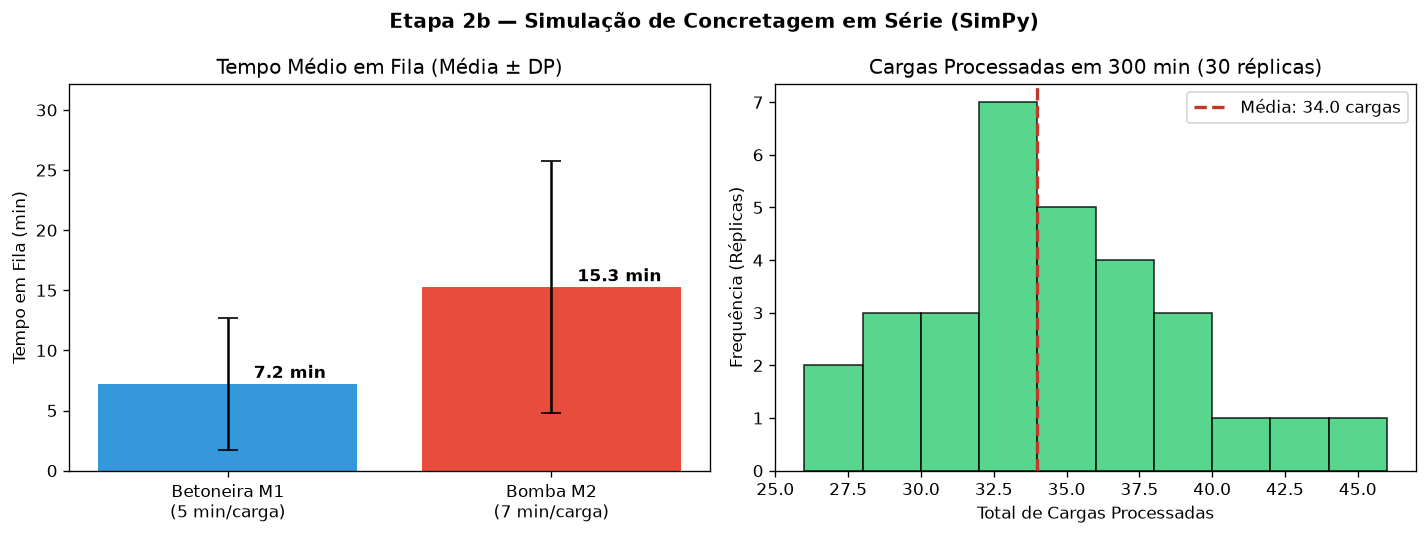

In [5]:
# ==============================================================================
# ETAPA 2b: SIMULAÇÃO DE CONCRETAGEM EM SÉRIE COM SIMPY (M1 -> M2)
# ==============================================================================

TEMPO_SIMULACAO = 300.0   # minutos (5 horas de operação contínua)
MEDIA_CHEGADA   = 8.0     # intervalo médio entre demandas de carga (min)
                          # premissa do grupo: maior que o serviço mais lento (7 min),
                          # para o sistema ser estável (com 5 min, a M1 opera com ρ = 1
                          # e as duas filas crescem sem limite, mascarando o gargalo)
MEDIA_M1        = 5.0     # tempo médio de preparo na Betoneira M1 (min)
MEDIA_M2        = 7.0     # tempo médio de bombeamento na Bomba M2 (min)
NUM_REPLICAS    = 30      # número de réplicas independentes

def executar_replica(seed):
    random.seed(seed)
    env = simpy.Environment()
    m1 = simpy.Resource(env, capacity=1)
    m2 = simpy.Resource(env, capacity=1)

    filas_m1, filas_m2 = [], []
    tempo_uso_m1, tempo_uso_m2 = 0.0, 0.0
    cargas_processadas = 0

    def processo_carga(env):
        nonlocal tempo_uso_m1, tempo_uso_m2, cargas_processadas

        # --- Estágio 1: Betoneira M1 ---
        chegada_m1 = env.now
        with m1.request() as req1:
            yield req1
            filas_m1.append(env.now - chegada_m1)
            duracao_m1 = random.expovariate(1.0 / MEDIA_M1)
            yield env.timeout(duracao_m1)
            tempo_uso_m1 += duracao_m1

        # --- Estágio 2: Bomba de Concreto M2 ---
        chegada_m2 = env.now
        with m2.request() as req2:
            yield req2
            filas_m2.append(env.now - chegada_m2)
            duracao_m2 = random.expovariate(1.0 / MEDIA_M2)
            yield env.timeout(duracao_m2)
            tempo_uso_m2 += duracao_m2

        cargas_processadas += 1

    def gerador_cargas(env):
        while True:
            env.process(processo_carga(env))
            yield env.timeout(random.expovariate(1.0 / MEDIA_CHEGADA))

    env.process(gerador_cargas(env))
    env.run(until=TEMPO_SIMULACAO)

    return {
        "Replica": seed - SEED + 1,
        "Cargas_Processadas": cargas_processadas,
        "Fila_Media_M1_min": np.mean(filas_m1) if filas_m1 else 0.0,
        "Fila_Media_M2_min": np.mean(filas_m2) if filas_m2 else 0.0,
        "Utilizacao_M1_%": min(100.0, (tempo_uso_m1 / TEMPO_SIMULACAO) * 100),
        "Utilizacao_M2_%": min(100.0, (tempo_uso_m2 / TEMPO_SIMULACAO) * 100),
    }

# Executa as 30 réplicas com seeds reprodutíveis (SEED, SEED+1, ...)
resultados_simpy = [executar_replica(SEED + i) for i in range(NUM_REPLICAS)]
df_simpy = pd.DataFrame(resultados_simpy)

# Estatísticas consolidadas
resumo_simpy = df_simpy.drop(columns=["Replica"]).agg(["mean", "std"]).T
resumo_simpy.columns = ["Média (30 réplicas)", "Desvio Padrão"]
display(resumo_simpy.round(2))

# Gargalo: recurso com maior utilização média, confirmado pela maior fila média
util_m1, util_m2 = df_simpy["Utilizacao_M1_%"].mean(), df_simpy["Utilizacao_M2_%"].mean()
fila_m1, fila_m2 = df_simpy["Fila_Media_M1_min"].mean(), df_simpy["Fila_Media_M2_min"].mean()
gargalo = "Bomba de Concreto M2" if util_m2 > util_m1 else "Betoneira M1"
confirmado = (util_m2 > util_m1) == (fila_m2 > fila_m1)
print(f"\nUtilização média: M1 = {util_m1:.1f}% | M2 = {util_m2:.1f}%")
print(f"Fila média:       M1 = {fila_m1:.1f} min | M2 = {fila_m2:.1f} min")
print(f">>> GARGALO IDENTIFICADO NA LINHA: {gargalo}"
      + ("" if confirmado else " (atenção: fila e utilização apontam recursos diferentes)"))

# Restaura a semente global (executar_replica altera o estado do gerador)
random.seed(SEED)

# Gráficos comparativos
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: Comparação do Tempo Médio em Fila (M1 vs M2)
medias_fila = [df_simpy["Fila_Media_M1_min"].mean(), df_simpy["Fila_Media_M2_min"].mean()]
stds_fila   = [df_simpy["Fila_Media_M1_min"].std(),  df_simpy["Fila_Media_M2_min"].std()]
axes[0].bar(["Betoneira M1\n(5 min/carga)", "Bomba M2\n(7 min/carga)"], medias_fila,
            yerr=stds_fila, capsize=6, color=["#3498DB", "#E74C3C"])
axes[0].set_title("Tempo Médio em Fila (Média ± DP)")
axes[0].set_ylim(0, max(m + d for m, d in zip(medias_fila, stds_fila)) * 1.25)
axes[0].set_ylabel("Tempo em Fila (min)")
for i, v in enumerate(medias_fila):
    axes[0].text(i + 0.08, v + 0.5, f"{v:.1f} min", ha="left", fontweight="bold")

# Gráfico 2: Distribuição de Cargas Processadas nas 30 réplicas
axes[1].hist(df_simpy["Cargas_Processadas"], bins=10, color="#2ECC71", edgecolor="black", alpha=0.8)
media_cargas = df_simpy["Cargas_Processadas"].mean()
axes[1].axvline(media_cargas, color="#C0392B", linestyle="--", lw=2, label=f"Média: {media_cargas:.1f} cargas")
axes[1].set_title(f"Cargas Processadas em {int(TEMPO_SIMULACAO)} min ({NUM_REPLICAS} réplicas)")
axes[1].set_xlabel("Total de Cargas Processadas")
axes[1].set_ylabel("Frequência (Réplicas)")
axes[1].legend()

plt.suptitle("Etapa 2b — Simulação de Concretagem em Série (SimPy)", fontweight="bold")
plt.tight_layout()
plt.savefig("outputs/graficos/etapa2b_simpy_gargalo.png", dpi=300)
plt.show()

**Análise dos resultados (2b)**
- Em 300 min, a linha processou em média **34,0 ± 4,5 cargas** nas 30 réplicas.
- A **Bomba de Concreto M2** é o **gargalo**: ela tem a maior utilização (**76,5%** contra **65,1%** da Betoneira M1) e o maior tempo médio em fila (**15,3 min** contra **7,2 min**). Isso é coerente com a teoria: a M2 é o recurso mais lento (7 min contra 5 min), e a capacidade máxima dela, de ≈ 300/7 ≈ 43 cargas, limita a vazão da linha inteira.
- O desvio padrão elevado mostra a alta variabilidade causada pelos tempos exponenciais. Por isso foram usadas várias réplicas, em vez de uma execução única.
- **Recomendação:** aumentar a capacidade da etapa de bombeamento (uma segunda bomba ou redução do tempo de bombeamento) traz mais ganho do que investir na betoneira. Melhorar a M1 só aumentaria a fila na frente da M2.
- **Limitações:** a média de fila considera apenas as cargas que chegaram a ser atendidas. Cargas ainda esperando no minuto 300 não entram na conta, o que subestima levemente a fila da M2. A utilização também conta apenas os serviços concluídos dentro do horizonte.

## Etapa 3 — Ontologia RDF/OWL e Consultas SPARQL

In [6]:
# ==============================================================================
# ETAPA 3 - ONTOLOGIA RDF/OWL E CONSULTAS SPARQL
# ==============================================================================

## Etapa 4 — Rede Neural MLP do Zero em NumPy (Forward Pass)

In [7]:
# ==============================================================================
# ETAPA 4 - REDE NEURAL MLP DO ZERO EM NUMPY
# ==============================================================================

# Reinicia a semente para pesos reprodutíveis
np.random.seed(SEED)

## Etapa 5 — Sistema de Inferência Fuzzy (Mamdani e Sugeno)


In [8]:
# ==============================================================================
# ETAPA 5 - SISTEMA DE INFERÊNCIA FUZZY
# ==============================================================================